In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

In [2]:
filename = Path('./data/processed/20210818_evening_staff_activities.csv')
df_staff_activities = pd.read_csv(filename, parse_dates=['start_time', 'end_time'])

dtypes = {'group_size': 'int', 'fully_captured': 'bool', 'visit_time': 'float'}
filename = Path('./data/processed/20210818_evening_guest_demand.csv')
df_guest_demand = pd.read_csv(filename, dtype=dtypes, parse_dates=['start_time', 'end_time'])

In [3]:
df_guest_demand

,visit_id,table_id,start_time,end_time,group_size,fully_captured,visit_time
0,2,14,2021-08-18 17:12:11,2021-08-18 17:37:41,3,False,NaN
1,3,15,2021-08-18 17:12:11,2021-08-18 17:29:20,3,False,NaN
2,7,16,2021-08-18 17:28:04,2021-08-18 17:33:43,2,False,NaN
3,5,54,2021-08-18 17:25:32,2021-08-18 18:32:51,2,True,4039.0
4,0,56,2021-08-18 17:12:06,2021-08-18 18:38:45,3,False,NaN
5,13,B2,2021-08-18 18:02:13,2021-08-18 18:52:38,1,True,3025.0
6,20,20,2021-08-18 18:28:32,2021-08-18 19:20:30,1,True,3118.0
7,15,12,2021-08-18 18:09:46,2021-08-18 19:41:48,2,True,5522.0
8,17,B3,2021-08-18 18:11:44,2021-08-18 20:01:30,2,True,6586.0
9,11,15,2021-08-18 17:43:09,2021-08-18 20:09:56,4,True,8807.0


In [4]:
import datetime

measurement_pause = (datetime.datetime(2021, 8, 18, 18, 59), datetime.datetime(2021, 8, 18, 20, 4))

measurement_pause


(datetime.datetime(2021, 8, 18, 18, 59), datetime.datetime(2021, 8, 18, 20, 4))

In [5]:
activities_per_table_per_visit_per_measurement_period = []
import datetime
activities_processed = None

for _, row in df_guest_demand.iterrows():
    table_id = row['table_id']
    start_time = row['start_time']
    end_time = row['end_time']
    
    if pd.isnull(end_time):
        end_time = datetime.datetime.now()
           
    df_activities = df_staff_activities[(df_staff_activities['table_id'] == table_id) & (df_staff_activities['start_time'] >= start_time) & (df_staff_activities['end_time'] <= end_time)]
    
    try:
        activities_processed = pd.concat([activities_processed, df_activities])
    except:
        activities_processed = df_activities
    
    df_activities_before = df_activities[df_activities['start_time'] <= measurement_pause[0]]
    df_activities_after = df_activities[df_activities['start_time'] > measurement_pause[0]]
    
    if len(df_activities) != len(df_activities_before) + len(df_activities_after):
        raise Exception('Missing')
    
    if len(df_activities) == 0:
        print(f'{table_id} ({start_time} - {end_time}) has no activities')
        continue
    
    if len(df_activities_before) > 0:    
        activities_per_table_per_visit_per_measurement_period.append(df_activities_before)
    if len(df_activities_after) > 0:    
        activities_per_table_per_visit_per_measurement_period.append(df_activities_after)
    


14 (2021-08-18 17:12:11 - 2021-08-18 17:37:41) has no activities
20 (2021-08-18 18:28:32 - 2021-08-18 19:20:30) has no activities
33 (2021-08-18 18:11:12 - 2021-08-18 20:13:42) has no activities
23 (2021-08-18 17:33:44 - 2021-12-02 13:45:54.215545) has no activities
B3 (2021-08-18 20:10:07 - 2021-12-02 13:45:54.244396) has no activities
33 (2021-08-18 20:54:24 - 2021-12-02 13:45:54.249536) has no activities


In [6]:
activities_to_process = pd.concat([activities_processed,df_staff_activities]).drop_duplicates(keep=False)

Compute:

1. Actvities per unit of time
2. Activity time distribution and best fit
3. Gap time distribution and best fit
4. Percentage of activities without guests at table

In [7]:
activities_per_hour = []
gaps_per_set = []

for activity_set in activities_per_table_per_visit_per_measurement_period:
        min_time = min(np.array(activity_set['start_time']))
        max_time = max(np.array(activity_set['end_time']))
        activity_count = len(activity_set)
        if activity_count <= 1: 
            continue
        meas_period = ((max_time - min_time)/np.timedelta64(1, 'h'))
        if meas_period > 0.5: 
            activities_per_hour.append(activity_count/meas_period)
        
        gaps_of_set = (np.array(activity_set['start_time'][1:activity_count]) - np.array(activity_set['start_time'][0:activity_count-1]))/np.timedelta64(1, 's') 
        gaps_per_set.append(gaps_of_set)
        
        if np.any(gaps_of_set > 1800):
            print(activity_set)
            print('')
        

    table_id staff_id          start_time            end_time activity_type
300       31        O 2021-08-18 20:10:30 2021-08-18 20:11:45           F&R
316       31        O 2021-08-18 20:22:08 2021-08-18 20:22:23             O
320       31       HM 2021-08-18 20:26:09 2021-08-18 20:26:16             S
323       31        O 2021-08-18 20:29:57 2021-08-18 20:30:02             R
355       31        O 2021-08-18 21:10:18 2021-08-18 21:10:27           P&R

    table_id staff_id          start_time            end_time activity_type
185       36       HM 2021-08-18 20:12:16 2021-08-18 20:12:29           S-R
187       36       HM 2021-08-18 20:12:47 2021-08-18 20:12:50             S
250       36        H 2021-08-18 21:14:22 2021-08-18 21:14:27             F
262       36        H 2021-08-18 21:25:50 2021-08-18 21:26:14             P

    table_id staff_id          start_time            end_time activity_type
179       56        H 2021-08-18 20:07:53 2021-08-18 20:08:05             R
190       

8.835992845889558


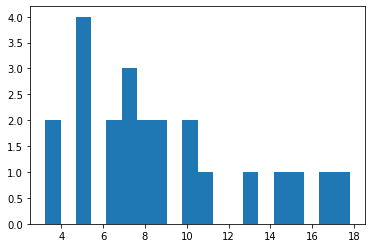

In [8]:
import matplotlib.pyplot as plt
hist = plt.hist(activities_per_hour, bins=20)
print(np.mean(activities_per_hour))


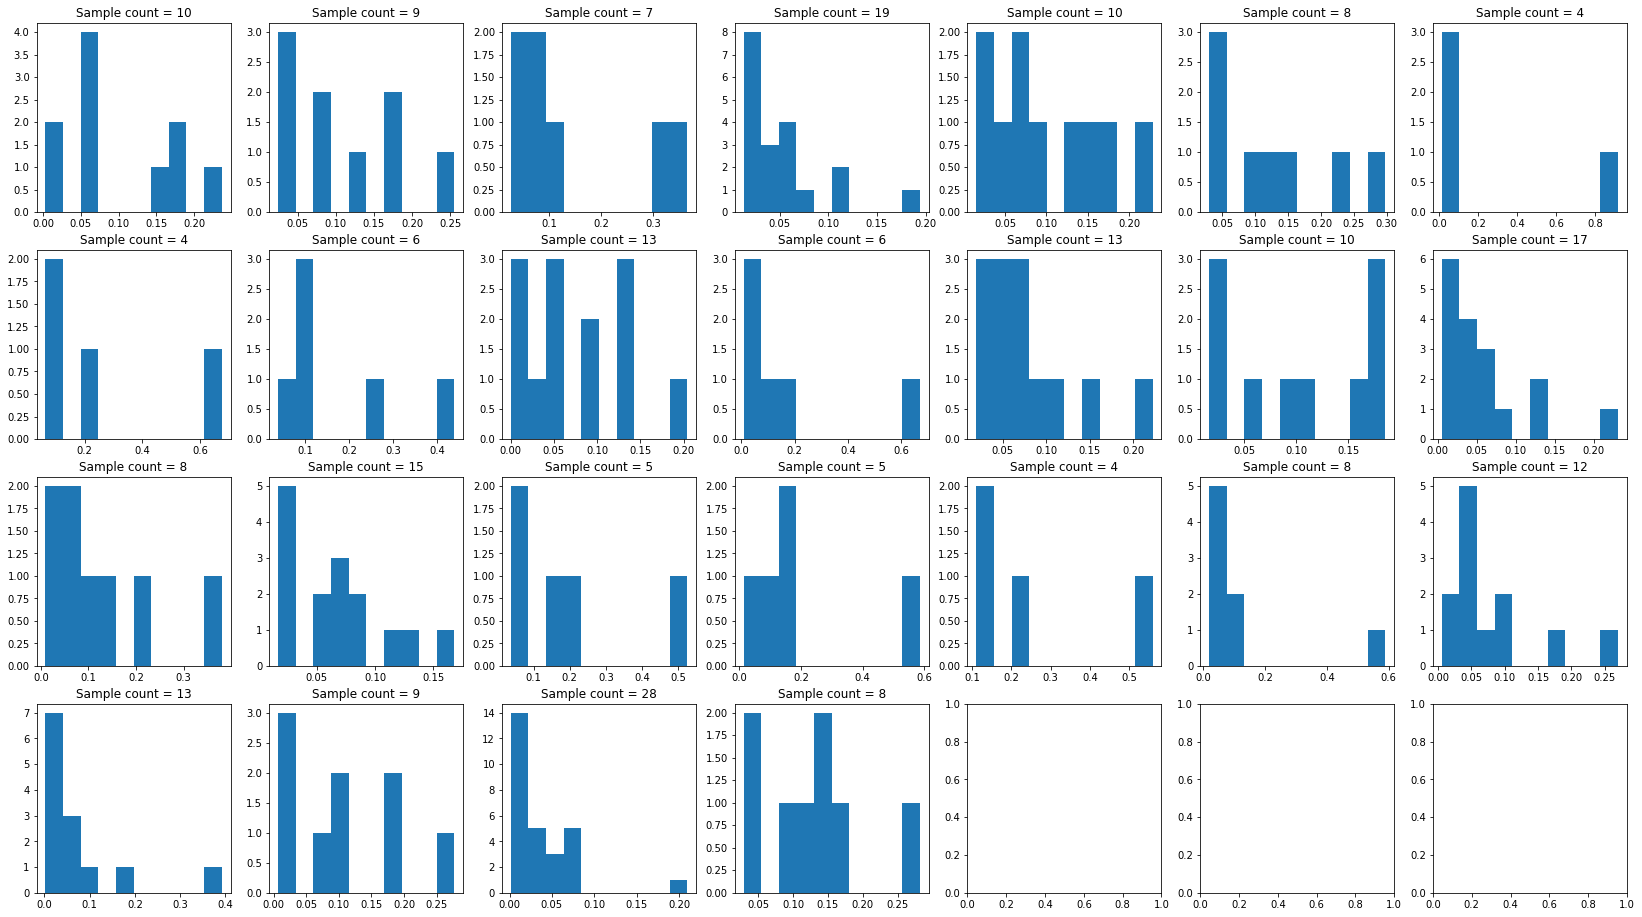

In [9]:
import matplotlib.pyplot as plt
from math import ceil

plt.rcParams['figure.figsize'] = [28.5,16]

gaps_per_set_filtered = [[gap/sum(gaps_of_set) for gap in gaps_of_set] for gaps_of_set in gaps_per_set if len(gaps_of_set) > 3]

col_count = 7
row_count = int(ceil(len(gaps_per_set_filtered)/col_count))
_, axes = plt.subplots(row_count, col_count)

axes = axes.flatten()

for ii, gaps_of_set in enumerate(gaps_per_set_filtered):
    hist = axes[ii].hist(gaps_of_set)
    axes[ii].set_title(f'Sample count = {len(gaps_of_set)}')


430.1507352941176


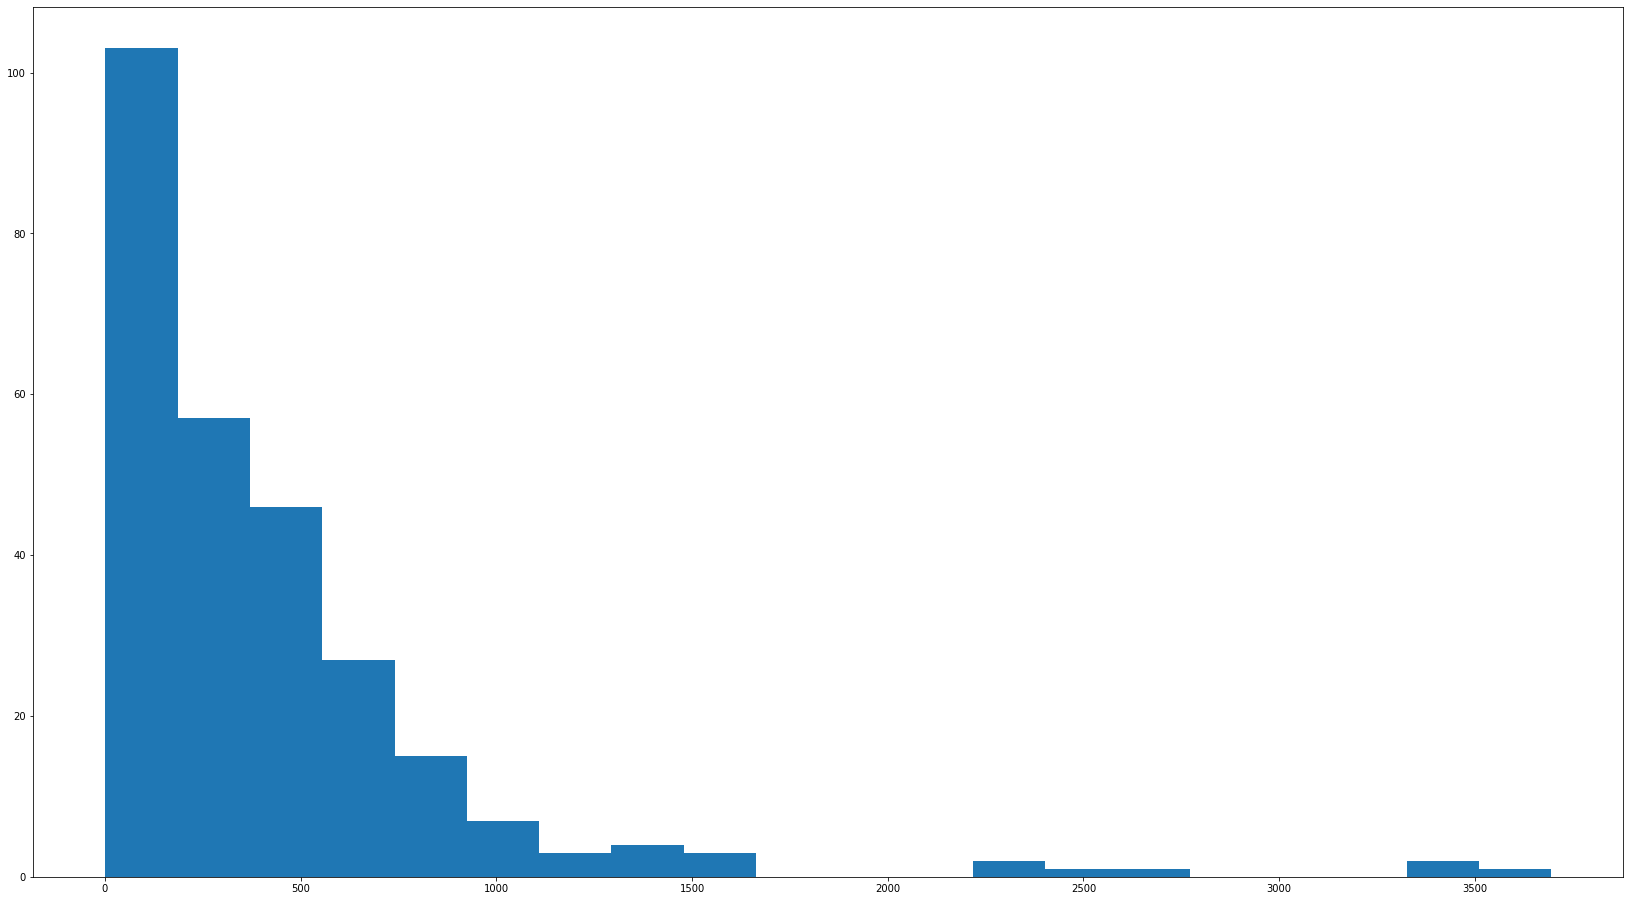

In [10]:
gaps = np.array([gap for gaps_of_set in gaps_per_set for gap in gaps_of_set])
import matplotlib.pyplot as plt
hist = plt.hist(gaps, bins=20)
print(np.mean(gaps))


In [11]:
sorted_gaps = np.sort(gaps)
for ii in range(20):
    print(f'{sorted_gaps[ii]:.1f} [s]')
    
print(f'max = {sorted_gaps[-1]:.1f} [s]')

for ii in range(20):
    print(f'{sorted_gaps[-ii]:.1f} [s]')


1.0 [s]
11.0 [s]
11.0 [s]
11.0 [s]
14.0 [s]
15.0 [s]
15.0 [s]
17.0 [s]
23.0 [s]
25.0 [s]
29.0 [s]
30.0 [s]
30.0 [s]
30.0 [s]
31.0 [s]
32.0 [s]
33.0 [s]
36.0 [s]
36.0 [s]
39.0 [s]
max = 3695.0 [s]
1.0 [s]
3695.0 [s]
3403.0 [s]
3386.0 [s]
2598.0 [s]
2421.0 [s]
2359.0 [s]
2346.0 [s]
1657.0 [s]
1653.0 [s]
1590.0 [s]
1459.0 [s]
1394.0 [s]
1324.0 [s]
1300.0 [s]
1268.0 [s]
1134.0 [s]
1114.0 [s]
1060.0 [s]
1055.0 [s]


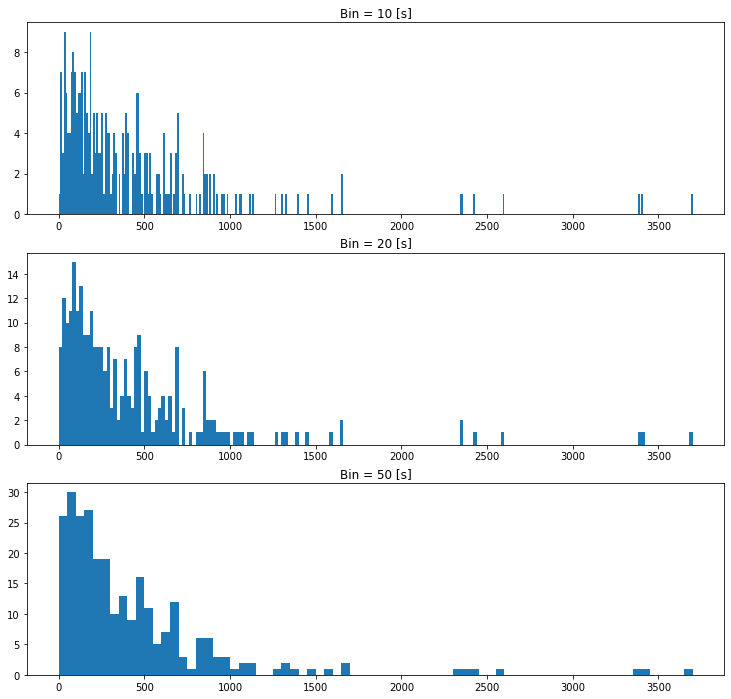

430.1507352941176


In [12]:
%matplotlib inline

gaps = np.array([gap for gaps_of_set in gaps_per_set for gap in gaps_of_set])
import matplotlib.pyplot as plt
bin_sizes = [10, 20, 50] # [s]

plt.rcParams['figure.figsize'] = [12.5,12]

_, axes = plt.subplots(len(bin_sizes))

for ii, bin_size in enumerate(bin_sizes):
    max_bin = np.ceil(np.max(gaps)/bin_size)*bin_size
    bins = np.arange(0, max_bin+bin_size, bin_size)
    hist = axes[ii].hist(gaps, bins=bins)
    axes[ii].set_title(f'Bin = {bin_size} [s]')
    
plt.show()
print(np.mean(gaps))

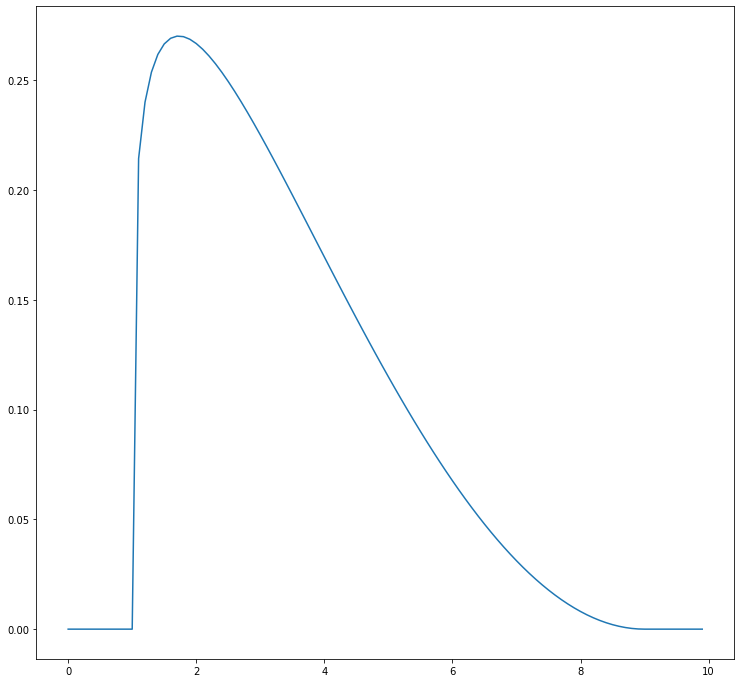

In [13]:
from scipy import stats
rv = stats.beta(1.2, 3, 1, 8)

x = np.arange(0,10,0.1)
plt.plot(x, rv.pdf(x))


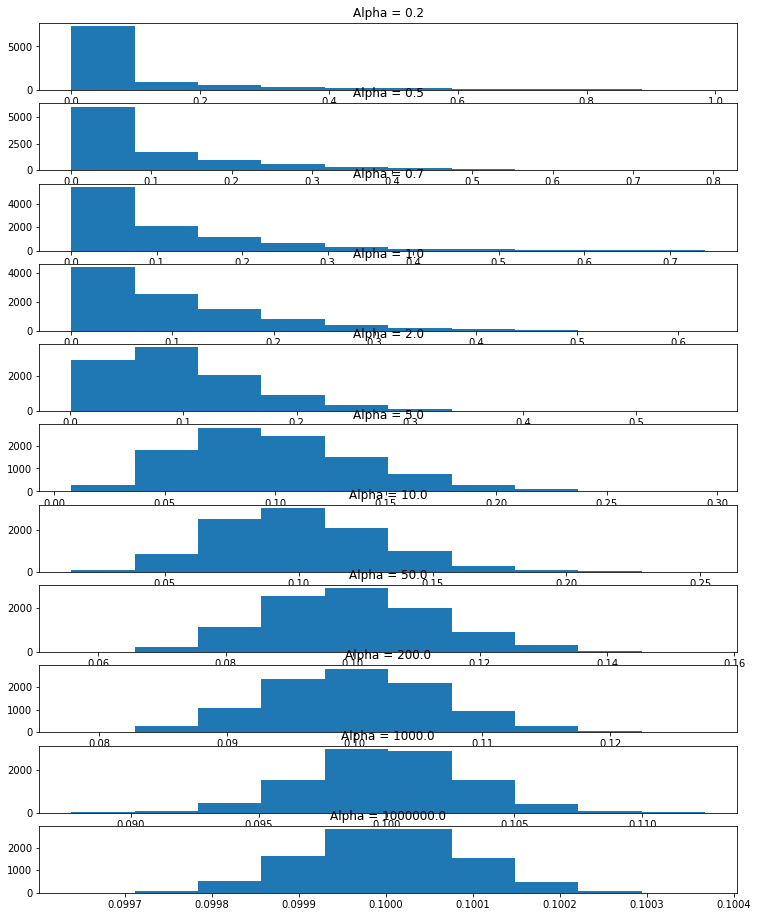

In [14]:



plt.rcParams['figure.figsize'] = [12.5,16]

alphas = [0.2, 0.5, 0.7, 1, 2, 5, 10, 50, 200, 1000, 1000000]
_, axes = plt.subplots(len(alphas))

for ii, alpha in enumerate(alphas):
    max_bin = np.ceil(np.max(gaps)/bin_size)*bin_size
    y = np.random.default_rng().dirichlet(10*[alpha], size=1000)
    y_flat = y.flatten()
    hist = axes[ii].hist(y_flat)
    axes[ii].set_title(f'Alpha = {alpha:.1f}')
    
plt.show()


(272,)
(272, 1)
[1.]


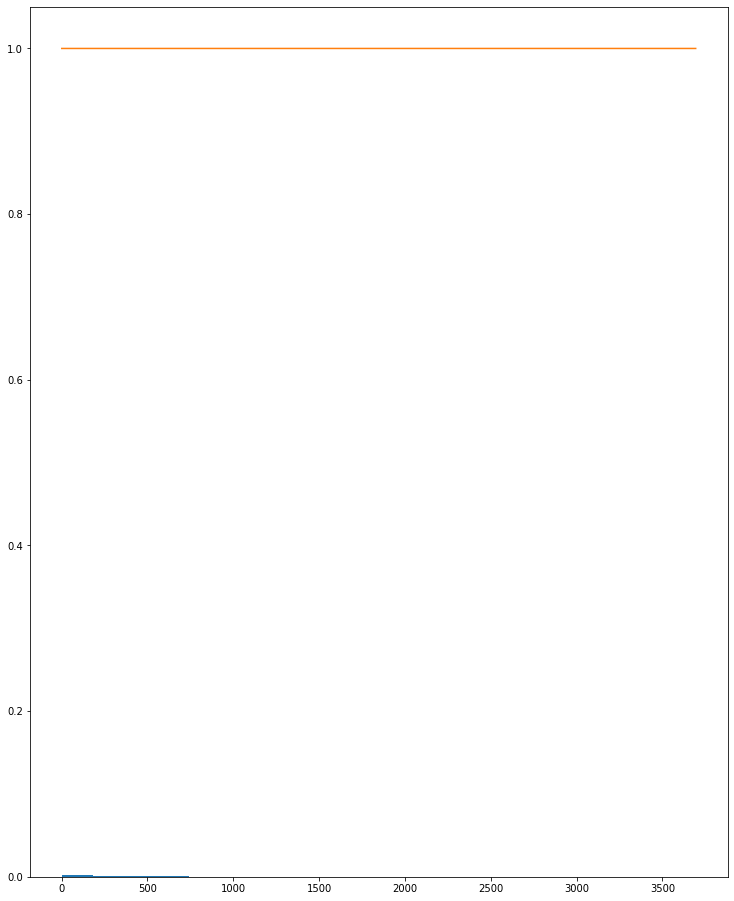

In [26]:
gaps = np.array([gap for gaps_of_set in gaps_per_set for gap in gaps_of_set])
import dirichlet

print(gaps.shape)
gaps = np.expand_dims(gaps, 1)
print(gaps.shape)

res = dirichlet.mle(gaps)

print(res)

import matplotlib.pyplot as plt
hist = plt.hist(gaps, bins=20, density=True)
pdf_func = dirichlet.pdf(np.array([1.0]))
x = np.expand_dims(np.arange(np.min(gaps), np.max(gaps), 1), 1)
plt.plot(x, pdf_func(x))



In [15]:
%%capture --no-stdout
from scipy import stats

list_of_dists = [nm for nm, _ in stats._distr_params.distcont]

results = []

for i in list_of_dists:
    dist = getattr(stats, i)
    try:
        param = dist.fit(gaps)
        a = stats.kstest(gaps, i, args=param)
    except:
        print(f'Could not fit {i}')
        continue
    results.append((i,a[0],a[1], param))
        
results.sort(key=lambda x:float(x[2]), reverse=True)

UsageError: Line magic function `%%capture` not found.


In [ ]:
for j in results:
    print("{}: statistic={}, pvalue={}".format(j[0], j[1], j[2]))
    
with open(Path('./data/stats/gaps_fits_starts.txt'), 'w') as f:
    f.write('name, statistic, pvalue, params\n')
    for j in results:
        f.write(f'{j[0]}, {j[1]:.4f}, {j[2]:.4f}, {j[3]}\n')

In [ ]:
import dirichlet

gaps[gaps<0] = 0

import matplotlib.pyplot as plt

plt.hist(gaps, bins = 50)

In [ ]:
gaps_exp = np.expand_dims(gaps, axis=1)

print(gaps_exp.shape)

res = dirichlet.mle(gaps_exp)

print(res)

In [ ]:
i = 'dirichlet'
dist = getattr(stats, i)
try:
    param = dist.fit(gaps)
    a = stats.kstest(gaps, i, args=param)
except:
    print(f'Could not fit {i}')    

In [ ]:
res

In [ ]:
rand_gen = np.random.default_rng()
a = rand_gen.binomial(1, 0.4, size=10).astype(bool)

a


In [ ]:
rand_gen = np.random.default_rng()

activityCount = 10
afterVisitActivityCount = 2
nextTime = 10
endTime = 3600

activityTimes = rand_gen.lognormal(2.90256, 0.937481, size=activityCount)
print(activityTimes)
gapFractions = rand_gen.dirichlet([1]*(activityCount - afterVisitActivityCount - 1))
print(gapFractions)
tStartLast = endTime - 30 - activityTimes[-(1+afterVisitActivityCount)]
print(tStartLast)
gaps = gapFractions*(tStartLast - nextTime)
print(gaps)
startTimes = np.append(np.append([nextTime], nextTime + np.cumsum(gaps)), [endTime]*afterVisitActivityCount)
print(startTimes)
baseBefore = rand_gen.binomial(1, 0.4, size=activityCount).astype(bool)
baseAfter = rand_gen.binomial(1, 0.3, size=activityCount).astype(bool)
print(baseBefore)
print(baseAfter)